<a href="https://colab.research.google.com/github/nieiiz/Plant-Disease-EfficientNetB0/blob/main/Plant_Disease_Efficient.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip install -q datasets huggingface_hub


In [ ]:

!pip install -q -U huggingface_hub

from huggingface_hub import hf_hub_download

zip_path = hf_hub_download(
    repo_id="mohanty/PlantVillage",
    repo_type="dataset",
    filename="data.zip",
    local_dir="/content/PlantVillage"
)

print("Download completed!")
print("File location:", zip_path)



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 13.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 2.2.0 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.2.0 which is incompatible.


data.zip:   0%|          | 0.00/2.18G [00:00<?, ?B/s]

Download completed!
File location: /content/PlantVillage/data.zip


In [ ]:

import zipfile
import os

zip_path = "/content/PlantVillage/data.zip"
extract_path = "/content/PlantVillage/extracted"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")

print("\nFolders:")
print(os.listdir(extract_path))


Extraction completed!

Folders:
['raw']


In [ ]:

import os

raw_path = "/content/PlantVillage/extracted/raw"

print("Folders inside raw:")
print(os.listdir(raw_path))


Folders inside raw:
['color', 'segmented', 'grayscale']


In [ ]:

import os

dataset_path = "/content/PlantVillage/extracted/raw/color"

classes = sorted([
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
])

total_images = 0

for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)

    num_images = len([
        file for file in os.listdir(class_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    total_images += num_images
    print(f"{class_name}: {num_images}")

print("\nNumber of classes:", len(classes))
print("Total images:", total_images)


Apple___Apple_scab: 630
Apple___Black_rot: 621
Apple___Cedar_apple_rust: 275
Apple___healthy: 1645
Blueberry___healthy: 1502
Cherry_(including_sour)___Powdery_mildew: 1052
Cherry_(including_sour)___healthy: 854
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 513
Corn_(maize)___Common_rust_: 1192
Corn_(maize)___Northern_Leaf_Blight: 985
Corn_(maize)___healthy: 1162
Grape___Black_rot: 1180
Grape___Esca_(Black_Measles): 1383
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076
Grape___healthy: 423
Orange___Haunglongbing_(Citrus_greening): 5507
Peach___Bacterial_spot: 2297
Peach___healthy: 360
Pepper,_bell___Bacterial_spot: 997
Pepper,_bell___healthy: 1478
Potato___Early_blight: 1000
Potato___Late_blight: 1000
Potato___healthy: 152
Raspberry___healthy: 371
Soybean___healthy: 5090
Squash___Powdery_mildew: 1835
Strawberry___Leaf_scorch: 1109
Strawberry___healthy: 456
Tomato___Bacterial_spot: 2127
Tomato___Early_blight: 1000
Tomato___Late_blight: 1909
Tomato___Leaf_Mold: 952
Tomato___Septoria

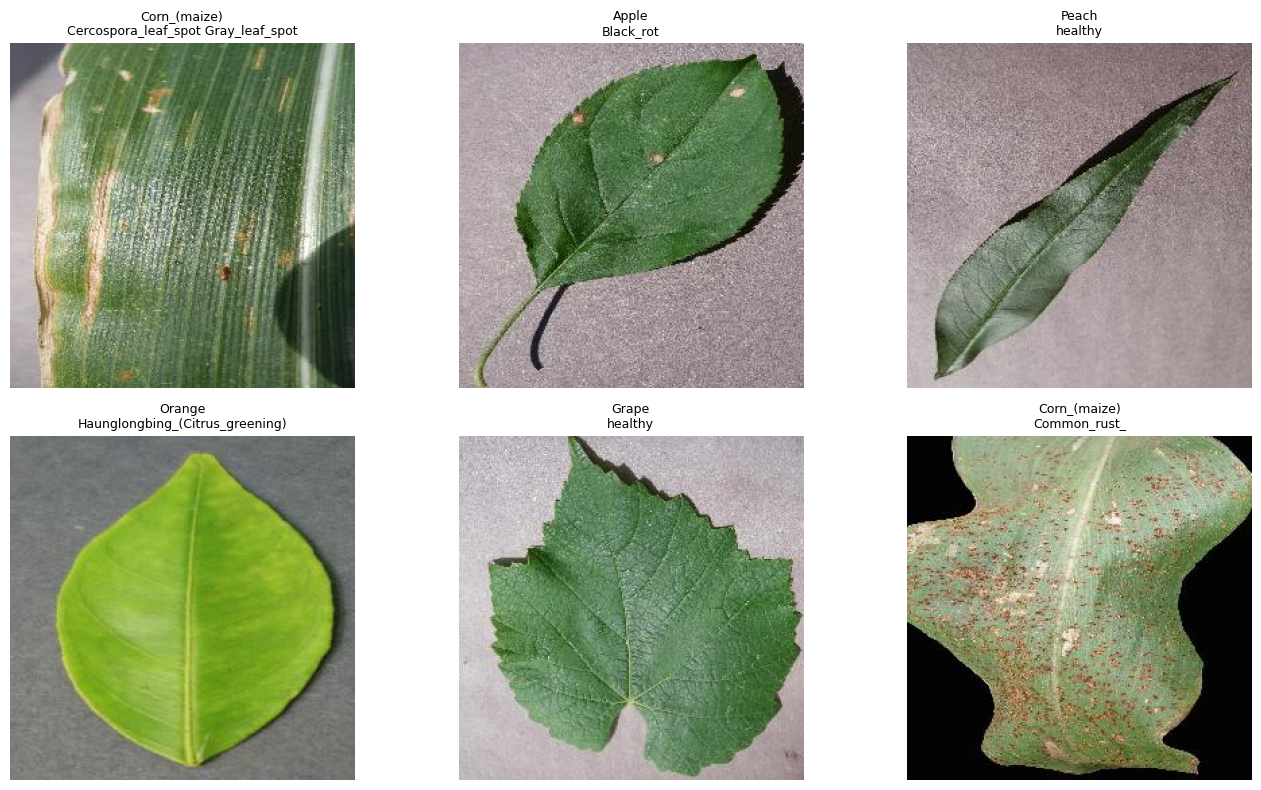

In [ ]:

import os
import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

selected_classes = random.sample(classes, 6)

plt.figure(figsize=(14, 8))

for i, class_name in enumerate(selected_classes):
    folder = os.path.join(dataset_path, class_name)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    image_name = random.choice(images)
    image_path = os.path.join(folder, image_name)

    img = Image.open(image_path).convert("RGB")

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(class_name.replace("___", "\n"), fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import os
import shutil

source = "/content/PlantVillage/data.zip"

destination_folder = "/content/drive/MyDrive/Plant_Disease_Project"

os.makedirs(destination_folder, exist_ok=True)

destination = os.path.join(
    destination_folder,
    "data.zip"
)

shutil.copy2(source, destination)

print("Dataset saved successfully!")
print("Saved in:", destination)

print("File size:",
      round(os.path.getsize(destination) / (1024**3), 2),
      "GB")


Dataset saved successfully!
Saved in: /content/drive/MyDrive/Plant_Disease_Project/data.zip
File size: 2.03 GB


In [ ]:

from huggingface_hub import hf_hub_download

train_file = hf_hub_download(
    repo_id="mohanty/PlantVillage",
    repo_type="dataset",
    filename="splits/color_train.txt"
)

test_file = hf_hub_download(
    repo_id="mohanty/PlantVillage",
    repo_type="dataset",
    filename="splits/color_test.txt"
)

with open(train_file) as f:
    train_images = [line.strip() for line in f if line.strip()]

with open(test_file) as f:
    test_images = [line.strip() for line in f if line.strip()]

print("Training images:", len(train_images))
print("Testing images:", len(test_images))
print("Total images:", len(train_images) + len(test_images))

color_train.txt:   0%|          | 0.00/4.15M [00:00<?, ?B/s]

color_test.txt:   0%|          | 0.00/1.02M [00:00<?, ?B/s]

Training images: 43596
Testing images: 10709
Total images: 54305


In [ ]:

import os

dataset_path = "/content/PlantVillage/extracted/raw/color"

print("First 3 training entries:")
for item in train_images[:3]:
    print(repr(item))

print("\nFirst 3 testing entries:")
for item in test_images[:3]:
    print(repr(item))

print("\nExample image folder:")
print(os.listdir(dataset_path)[:3])


First 3 training entries:
'raw/color/Raspberry___healthy/a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL 9155.JPG'
'raw/color/Raspberry___healthy/368f3c83-5bd2-4906-b418-57b6ceff9bfe___Mary_HL 9160.JPG'
'raw/color/Raspberry___healthy/98226f66-15a1-40d5-9b62-04ae5b4fd8d5___Mary_HL 9159.JPG'

First 3 testing entries:
'raw/color/Raspberry___healthy/6c2e049f-38c9-42c5-864f-613e6e12d59e___Mary_HL 6318.JPG'
'raw/color/Raspberry___healthy/8e8297fd-5e23-44f2-be98-92f7b8908f81___Mary_HL 6315.JPG'
'raw/color/Raspberry___healthy/67cff824-a58b-40c3-93a2-7dead429b1f0___Mary_HL 6322.JPG'

Example image folder:
['Apple___healthy', 'Pepper,_bell___Bacterial_spot', 'Blueberry___healthy']


In [ ]:

import os

base_path = "/content/PlantVillage/extracted"

# Verify paths exist
missing_train = [
    p for p in train_images
    if not os.path.isfile(os.path.join(base_path, p))
]

missing_test = [
    p for p in test_images
    if not os.path.isfile(os.path.join(base_path, p))
]

print("Missing training images:", len(missing_train))
print("Missing testing images:", len(missing_test))

# Check overlap
overlap = set(train_images) & set(test_images)
print("Train/Test overlap:", len(overlap))

# Examine image filenames
print("\nSample filenames:")
for p in train_images[:10]:
    print(os.path.basename(p))


Missing training images: 0
Missing testing images: 0
Train/Test overlap: 0

Sample filenames:
a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL 9155.JPG
368f3c83-5bd2-4906-b418-57b6ceff9bfe___Mary_HL 9160.JPG
98226f66-15a1-40d5-9b62-04ae5b4fd8d5___Mary_HL 9159.JPG
e2bc5cd9-a590-4b06-a610-dec52f74ae1e___Mary_HL 9163.JPG
de3b86c7-8f0b-4cd8-ab11-2450fff0ec52___Mary_HL 9154.JPG
dbaa5f62-187f-422b-ac84-12c6e7b12025___Mary_HL 9164.JPG
8e5806cd-b3f0-4737-8be0-9b7726d8b33c___Mary_HL 9165.JPG
432379a4-dc5d-49fa-9d75-ebe05a1e01eb___Mary_HL 9161.JPG
599c43e6-e742-4bc6-92a1-a1ebe4fa820a___Mary_HL 9158.JPG
12a43ab6-1f18-4b10-9fb4-4865b216d28e___Mary_HL 9156.JPG


In [ ]:

from sklearn.model_selection import train_test_split
import os
import json

# Extract class labels from file paths
train_labels = [
    p.split("/")[2] for p in train_images
]

# Create training and validation splits
train_paths, val_paths = train_test_split(
    train_images,
    test_size=0.10,
    random_state=42,
    stratify=train_labels
)

# Confirm no overlap
assert not (set(train_paths) & set(val_paths))
assert not (set(train_paths) & set(test_images))
assert not (set(val_paths) & set(test_images))

print("Training:", len(train_paths))
print("Validation:", len(val_paths))
print("Testing:", len(test_images))

# Save splits to Google Drive
save_dir = "/content/drive/MyDrive/Plant_Disease_Project"
os.makedirs(save_dir, exist_ok=True)

splits = {
    "train": train_paths,
    "validation": val_paths,
    "test": test_images
}

with open(
    os.path.join(save_dir, "data_splits.json"),
    "w"
) as f:
    json.dump(splits, f, indent=2)

print("\nSplits saved successfully!")


Training: 39236
Validation: 4360
Testing: 10709

Splits saved successfully!


In [ ]:

import tensorflow as tf
import os
import json

# Dataset settings
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

base_path = "/content/PlantVillage/extracted"

# Load saved splits from Google Drive
splits_file = "/content/drive/MyDrive/Plant_Disease_Project/data_splits.json"

with open(splits_file, "r") as f:
    splits = json.load(f)

train_paths = splits["train"]
val_paths = splits["validation"]
test_paths = splits["test"]

# Class names
class_names = sorted(set(
    p.split("/")[2] for p in (
        train_paths + val_paths + test_paths
    )
))

num_classes = len(class_names)

print("TensorFlow version:", tf.__version__)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", num_classes)
print("Train images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Test images:", len(test_paths))


TensorFlow version: 2.21.0
Image size: (224, 224)
Batch size: 32
Number of classes: 38
Train images: 39236
Validation images: 4360
Test images: 10709


In [ ]:

import tensorflow as tf
import os

AUTOTUNE = tf.data.AUTOTUNE

# Convert class names to numeric labels
class_to_index = {
    name: i for i, name in enumerate(class_names)
}

def prepare_paths_and_labels(paths):
    full_paths = [
        os.path.join(base_path, p)
        for p in paths
    ]

    labels = [
        class_to_index[p.split("/")[2]]
        for p in paths
    ]

    return full_paths, labels


def load_image(path, label):
    # Read image from disk
    image = tf.io.read_file(path)

    # Decode image as RGB
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    # Set image dimensions
    image.set_shape([None, None, 3])

    # Resize to 224 x 224
    image = tf.image.resize(image, IMG_SIZE)

    # EfficientNetB0 expects pixel values 0-255
    image = tf.cast(image, tf.float32)

    return image, label


def create_dataset(paths, training=False):
    full_paths, labels = prepare_paths_and_labels(paths)

    ds = tf.data.Dataset.from_tensor_slices(
        (full_paths, labels)
    )

    if training:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=42,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)

    ds = ds.prefetch(AUTOTUNE)

    return ds


train_ds = create_dataset(train_paths, training=True)
val_ds = create_dataset(val_paths)
test_ds = create_dataset(test_paths)

print("Data Pipeline created successfully!")
print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))


Data Pipeline created successfully!
Training batches: 1227
Validation batches: 137
Testing batches: 335


In [ ]:

import os

folder = "/content/drive/MyDrive/Plant_Disease_Project"

required_files = ["data.zip", "data_splits.json"]

for filename in required_files:
    file_path = os.path.join(folder, filename)

    if os.path.isfile(file_path):
        print("✅ Saved:", filename)
    else:
        print("❌ Missing:", filename)


✅ Saved: data.zip
✅ Saved: data_splits.json


In [ ]:

import os

PROJECT_DIR = "/content/drive/MyDrive/Plant_Disease_Project"

folders = [
    "models",
    "results",
    "plots",
    "checkpoints",
    "logs"
]

for folder in folders:
    os.makedirs(
        os.path.join(PROJECT_DIR, folder),
        exist_ok=True
    )

print("✅ Project folders created successfully!")

print("\nProject files and folders:")
for item in sorted(os.listdir(PROJECT_DIR)):
    print("📁" if os.path.isdir(
        os.path.join(PROJECT_DIR, item)
    ) else "📄", item)


✅ Project folders created successfully!

Project files and folders:
📁 checkpoints
📄 data.zip
📄 data_splits.json
📁 logs
📁 models
📁 plots
📁 results


In [ ]:

import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")

print("Available GPUs:", gpus)

if gpus:
    print("✅ GPU is ready!")
else:
    print("❌ GPU not detected")


Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✅ GPU is ready!


In [ ]:

import os

drive_path = "/content/drive/MyDrive"

if os.path.isdir(drive_path):
    print("✅ Google Drive is already accessible!")
    print("Files:", os.listdir(drive_path)[:10])
else:
    print("⚠️ Google Drive is not accessible.")
    print("Mount folder contents:",
          os.listdir("/content/drive")
          if os.path.isdir("/content/drive")
          else "Folder does not exist")



✅ Google Drive is already accessible!
Files: ['Plant_Disease_Project']


In [ ]:

import os
import zipfile
import json

# Project paths
PROJECT_DIR = "/content/drive/MyDrive/Plant_Disease_Project"

zip_path = os.path.join(PROJECT_DIR, "data.zip")
splits_path = os.path.join(PROJECT_DIR, "data_splits.json")

base_path = "/content/PlantVillage/extracted"

# Verify saved files
assert os.path.isfile(zip_path), "Dataset ZIP not found!"
assert os.path.isfile(splits_path), "Splits file not found!"

print("✅ Saved files found!")

# Extract dataset if needed
sample_folder = os.path.join(base_path, "raw", "color")

if not os.path.isdir(sample_folder):
    os.makedirs(base_path, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(base_path)

    print("✅ Dataset extracted!")
else:
    print("✅ Dataset folder already exists!")

# Restore splits
with open(splits_path, "r") as f:
    splits = json.load(f)

train_paths = splits["train"]
val_paths = splits["validation"]
test_paths = splits["test"]

# Restore classes
class_names = sorted(set(
    p.split("/")[2]
    for p in train_paths + val_paths + test_paths
))

num_classes = len(class_names)

# Verify image paths
all_paths = train_paths + val_paths + test_paths

missing = sum(
    not os.path.isfile(os.path.join(base_path, p))
    for p in all_paths
)

print("\nTraining:", len(train_paths))
print("Validation:", len(val_paths))
print("Testing:", len(test_paths))
print("Number of classes:", num_classes)
print("Missing images:", missing)


✅ Saved files found!
✅ Dataset folder already exists!

Training: 39236
Validation: 4360
Testing: 10709
Number of classes: 38
Missing images: 0


In [ ]:

import tensorflow as tf
import os

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Convert class names to numbers
class_to_index = {
    name: i for i, name in enumerate(class_names)
}

def prepare_paths_and_labels(paths):
    full_paths = [
        os.path.join(base_path, p)
        for p in paths
    ]

    labels = [
        class_to_index[p.split("/")[2]]
        for p in paths
    ]

    return full_paths, labels


def load_image(path, label):
    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label


def create_dataset(paths, training=False):
    full_paths, labels = prepare_paths_and_labels(paths)

    ds = tf.data.Dataset.from_tensor_slices(
        (full_paths, labels)
    )

    if training:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=42,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds


train_ds = create_dataset(train_paths, training=True)
val_ds = create_dataset(val_paths)
test_ds = create_dataset(test_paths)

print("✅ Data Pipeline is ready!")
print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))


✅ Data Pipeline is ready!
Training batches: 1227
Validation batches: 137
Testing batches: 335


In [ ]:

import tensorflow as tf

print("GPUs:", tf.config.list_physical_devices("GPU"))


GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, Model

tf.keras.utils.set_random_seed(42)

# Load pretrained EfficientNetB0
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Build baseline model
inputs = layers.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    num_classes,
    activation="softmax"
)(x)

baseline_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="Baseline_EfficientNetB0"
)

# Compile model
baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

baseline_model.summary()

print("\n✅ Baseline EfficientNetB0 created successfully!")


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "Baseline_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,098,249 (15.63 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


✅ Baseline EfficientNetB0 created successfully!


In [ ]:

import os
import tensorflow as tf

# Project folders
PROJECT_DIR = "/content/drive/MyDrive/Plant_Disease_Project"

checkpoint_dir = os.path.join(
    PROJECT_DIR, "checkpoints"
)

results_dir = os.path.join(
    PROJECT_DIR, "results"
)

os.makedirs(checkpoint_dir, exist_ok=True)
os.makedirs(results_dir, exist_ok=True)

# Model save path
baseline_checkpoint = os.path.join(
    checkpoint_dir,
    "baseline_best.keras"
)

# Save best model automatically
checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=baseline_checkpoint,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Stop training if validation stops improving
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Save training metrics after every epoch
csv_logger = tf.keras.callbacks.CSVLogger(
    os.path.join(results_dir, "baseline_training_log.csv"),
    append=False
)

print("✅ Training callbacks configured!")
print("Checkpoint path:", baseline_checkpoint)


✅ Training callbacks configured!
Checkpoint path: /content/drive/MyDrive/Plant_Disease_Project/checkpoints/baseline_best.keras


In [ ]:

import time

start_time = time.time()

history_baseline = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        checkpoint_callback,
        early_stopping,
        csv_logger
    ],
    verbose=1
)

training_time = time.time() - start_time

print("\n✅ Baseline training completed!")
print(
    "Training time:",
    round(training_time / 60, 2),
    "minutes"
)

print("Best model saved at:", baseline_checkpoint)


Epoch 1/10
1226/1227 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.9725 - loss: 0.0915
Epoch 1: val_loss improved from 0.07955 to 0.07386, saving model to /content/drive/MyDrive/Plant_Disease_Project/checkpoints/baseline_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Plant_Disease_Project/checkpoints/baseline_best.keras
1227/1227 ━━━━━━━━━━━━━━━━━━━━ 61s 50ms/step - accuracy: 0.9705 - loss: 0.0953 - val_accuracy: 0.9782 - val_loss: 0.0739
Epoch 2/10
1226/1227 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.9712 - loss: 0.0887
Epoch 2: val_loss improved from 0.07386 to 0.07239, saving model to /content/drive/MyDrive/Plant_Disease_Project/checkpoints/baseline_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Plant_Disease_Project/checkpoints/baseline_best.keras
1227/1227 ━━━━━━━━━━━━━━━━━━━━ 69s 40ms/step - accuracy: 0.9712 - loss: 0.0916 - val_accuracy: 0.9757 - val_loss: 0.0724
Epoch 3/10
1225/1227 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy:

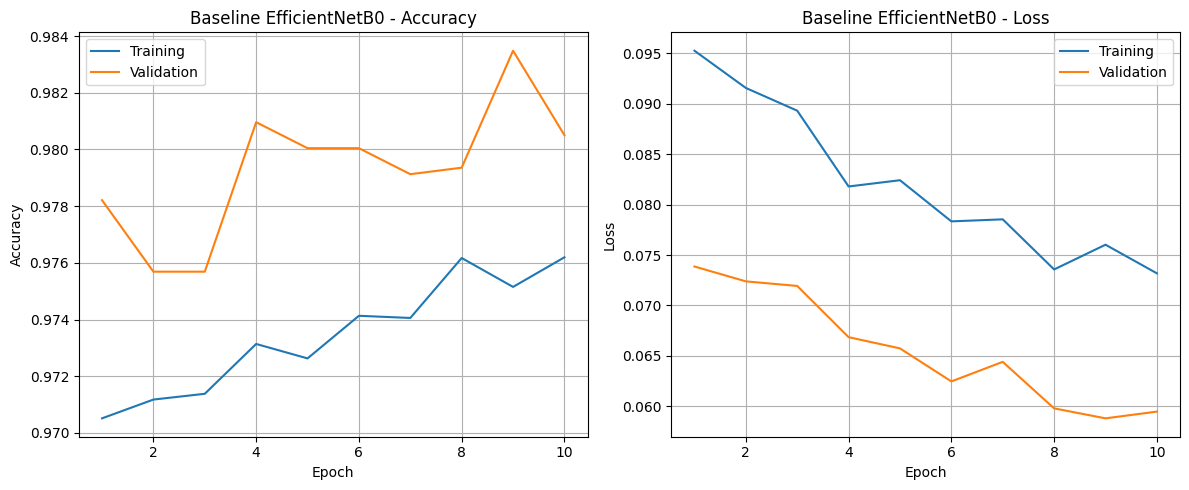

✅ Training curves saved successfully!

Best epoch: 9
Best Validation Accuracy: 98.35 %
Best Validation Loss: 0.0588


In [ ]:

import matplotlib.pyplot as plt
import os

# Get training history
history = history_baseline.history

epochs_range = range(1, len(history["accuracy"]) + 1)

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["accuracy"], label="Training")
plt.plot(epochs_range, history["val_accuracy"], label="Validation")
plt.title("Baseline EfficientNetB0 - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history["loss"], label="Training")
plt.plot(epochs_range, history["val_loss"], label="Validation")
plt.title("Baseline EfficientNetB0 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()

# Save figure to Google Drive
plot_dir = os.path.join(PROJECT_DIR, "plots")
os.makedirs(plot_dir, exist_ok=True)

plt.savefig(
    os.path.join(plot_dir, "baseline_training_curves.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Training curves saved successfully!")

# Show best validation performance
best_epoch = min(
    range(len(history["val_loss"])),
    key=lambda i: history["val_loss"][i]
)

print("\nBest epoch:", best_epoch + 1)
print("Best Validation Accuracy:",
      round(history["val_accuracy"][best_epoch] * 100, 2), "%")
print("Best Validation Loss:",
      round(history["val_loss"][best_epoch], 4))


In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, Model

tf.keras.utils.set_random_seed(42)

# Data Augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomBrightness(0.15, value_range=(0, 255)),
    layers.RandomContrast(0.15),
], name="data_augmentation")

# Load EfficientNetB0 with ImageNet weights
aug_base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
aug_base_model.trainable = False

# Build augmented model
inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

x = aug_base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    num_classes,
    activation="softmax"
)(x)

augmented_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="Augmented_EfficientNetB0"
)

# Compile model
augmented_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

augmented_model.summary()

print("\n✅ Augmented EfficientNetB0 created successfully!")


Model: "Augmented_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,098,249 (15.63 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


✅ Augmented EfficientNetB0 created successfully!


In [ ]:

import os
import tensorflow as tf

PROJECT_DIR = "/content/drive/MyDrive/Plant_Disease_Project"

checkpoint_dir = os.path.join(
    PROJECT_DIR, "checkpoints"
)

results_dir = os.path.join(
    PROJECT_DIR, "results"
)

os.makedirs(checkpoint_dir, exist_ok=True)
os.makedirs(results_dir, exist_ok=True)

# Save best augmented model
augmented_checkpoint = os.path.join(
    checkpoint_dir,
    "augmented_best.keras"
)

aug_checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=augmented_checkpoint,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Stop training when validation stops improving
aug_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Save training results
aug_csv_logger = tf.keras.callbacks.CSVLogger(
    os.path.join(
        results_dir,
        "augmented_training_log.csv"
    ),
    append=False
)

print("✅ Augmented training callbacks configured!")
print("Checkpoint path:", augmented_checkpoint)

# Verify baseline checkpoint is preserved
baseline_path = os.path.join(
    checkpoint_dir,
    "baseline_best.keras"
)

print("Baseline checkpoint exists:",
      os.path.isfile(baseline_path))


✅ Augmented training callbacks configured!
Checkpoint path: /content/drive/MyDrive/Plant_Disease_Project/checkpoints/augmented_best.keras
Baseline checkpoint exists: True


In [ ]:

import time

# Start training timer
start_time = time.time()

# Train augmented model
history_augmented = augmented_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        aug_checkpoint_callback,
        aug_early_stopping,
        aug_csv_logger
    ],
    verbose=1
)

# Calculate training time
training_time_augmented = time.time() - start_time

print("\n✅ Augmented training completed!")

print(
    "Training time:",
    round(training_time_augmented / 60, 2),
    "minutes"
)

print("Best model saved at:", augmented_checkpoint)


Epoch 1/10
1226/1227 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.7162 - loss: 1.1848
Epoch 1: val_loss improved from None to 0.25557, saving model to /content/drive/MyDrive/Plant_Disease_Project/checkpoints/augmented_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Plant_Disease_Project/checkpoints/augmented_best.keras
1227/1227 ━━━━━━━━━━━━━━━━━━━━ 127s 92ms/step - accuracy: 0.8363 - loss: 0.6745 - val_accuracy: 0.9360 - val_loss: 0.2556
Epoch 2/10
1226/1227 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9199 - loss: 0.2945
Epoch 2: val_loss improved from 0.25557 to 0.17965, saving model to /content/drive/MyDrive/Plant_Disease_Project/checkpoints/augmented_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Plant_Disease_Project/checkpoints/augmented_best.keras
1227/1227 ━━━━━━━━━━━━━━━━━━━━ 110s 89ms/step - accuracy: 0.9255 - loss: 0.2702 - val_accuracy: 0.9463 - val_loss: 0.1796
Epoch 3/10
1226/1227 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accura

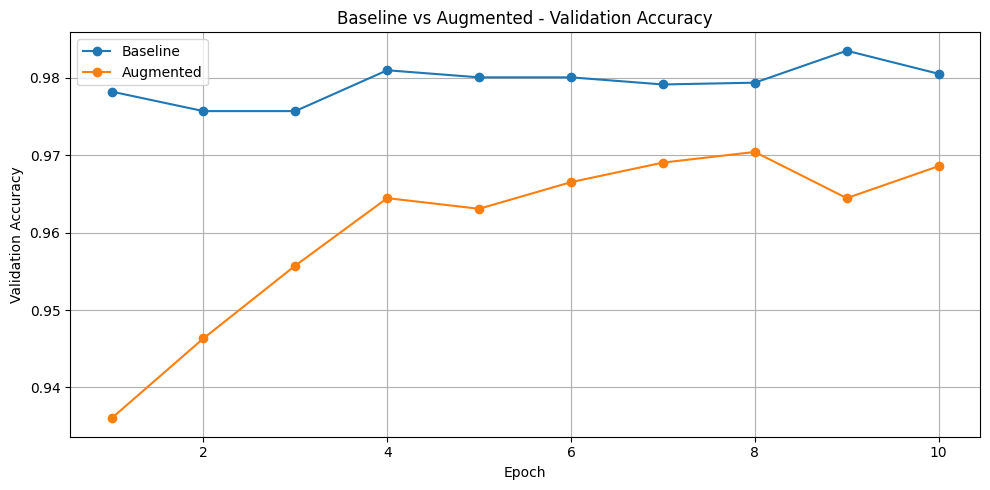

✅ Comparison completed!

Baseline:
Best Epoch: 9
Validation Accuracy: 98.35 %
Validation Loss: 0.0588

Augmented:
Best Epoch: 10
Validation Accuracy: 96.86 %
Validation Loss: 0.0973


In [ ]:

import matplotlib.pyplot as plt
import pandas as pd
import os

PROJECT_DIR = "/content/drive/MyDrive/Plant_Disease_Project"

results_dir = os.path.join(PROJECT_DIR, "results")
plots_dir = os.path.join(PROJECT_DIR, "plots")
os.makedirs(plots_dir, exist_ok=True)

# Read saved training results
baseline_log = pd.read_csv(
    os.path.join(results_dir, "baseline_training_log.csv")
)

augmented_log = pd.read_csv(
    os.path.join(results_dir, "augmented_training_log.csv")
)

# Plot validation accuracy comparison
plt.figure(figsize=(10, 5))

plt.plot(
    baseline_log["epoch"] + 1,
    baseline_log["val_accuracy"],
    marker="o",
    label="Baseline"
)

plt.plot(
    augmented_log["epoch"] + 1,
    augmented_log["val_accuracy"],
    marker="o",
    label="Augmented"
)

plt.title("Baseline vs Augmented - Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(plots_dir, "validation_accuracy_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Identify best epochs using minimum validation loss
baseline_best = baseline_log.loc[
    baseline_log["val_loss"].idxmin()
]

augmented_best = augmented_log.loc[
    augmented_log["val_loss"].idxmin()
]

print("✅ Comparison completed!")

print("\nBaseline:")
print("Best Epoch:", int(baseline_best["epoch"]) + 1)
print("Validation Accuracy:",
      round(baseline_best["val_accuracy"] * 100, 2), "%")
print("Validation Loss:",
      round(baseline_best["val_loss"], 4))

print("\nAugmented:")
print("Best Epoch:", int(augmented_best["epoch"]) + 1)
print("Validation Accuracy:",
      round(augmented_best["val_accuracy"] * 100, 2), "%")
print("Validation Loss:",
      round(augmented_best["val_loss"], 4))


In [ ]:

import tensorflow as tf
import os
import json

PROJECT_DIR = "/content/drive/MyDrive/Plant_Disease_Project"

# Load best saved models
baseline_best_model = tf.keras.models.load_model(
    os.path.join(PROJECT_DIR, "checkpoints", "baseline_best.keras")
)

augmented_best_model = tf.keras.models.load_model(
    os.path.join(PROJECT_DIR, "checkpoints", "augmented_best.keras")
)

print("✅ Both models loaded successfully!")

# Evaluate on clean test images
baseline_loss, baseline_acc = baseline_best_model.evaluate(
    test_ds,
    verbose=1
)

augmented_loss, augmented_acc = augmented_best_model.evaluate(
    test_ds,
    verbose=1
)

# Show results
print("\n===== CLEAN TEST RESULTS =====")

print("Baseline Test Accuracy:",
      round(baseline_acc * 100, 2), "%")

print("Baseline Test Loss:",
      round(baseline_loss, 4))

print("Augmented Test Accuracy:",
      round(augmented_acc * 100, 2), "%")

print("Augmented Test Loss:",
      round(augmented_loss, 4))

# Save results to Google Drive
results = {
    "baseline": {
        "test_accuracy": float(baseline_acc),
        "test_loss": float(baseline_loss)
    },
    "augmented": {
        "test_accuracy": float(augmented_acc),
        "test_loss": float(augmented_loss)
    }
}

results_path = os.path.join(
    PROJECT_DIR, "results", "clean_test_results.json"
)

with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

print("\n✅ Clean test results saved!")


✅ Both models loaded successfully!
335/335 ━━━━━━━━━━━━━━━━━━━━ 27s 57ms/step - accuracy: 0.9756 - loss: 0.0750
335/335 ━━━━━━━━━━━━━━━━━━━━ 30s 80ms/step - accuracy: 0.9618 - loss: 0.1179

===== CLEAN TEST RESULTS =====
Baseline Test Accuracy: 97.56 %
Baseline Test Loss: 0.075
Augmented Test Accuracy: 96.18 %
Augmented Test Loss: 0.1179

✅ Clean test results saved!


In [ ]:

import tensorflow as tf
import numpy as np

# Make experiments reproducible
tf.random.set_seed(42)

# 1. Gaussian Noise
def add_gaussian_noise(image, severity=0.15):
    noise = tf.random.normal(
        tf.shape(image),
        mean=0.0,
        stddev=severity * 255.0
    )
    return tf.clip_by_value(image + noise, 0.0, 255.0)


# 2. Gaussian Blur
def add_gaussian_blur(image, severity=1.0):
    kernel_size = 5

    x = tf.range(
        -(kernel_size // 2),
        kernel_size // 2 + 1,
        dtype=tf.float32
    )

    kernel = tf.exp(-(x ** 2) / (2 * severity ** 2))
    kernel = kernel / tf.reduce_sum(kernel)

    kernel_2d = tf.tensordot(kernel, kernel, axes=0)
    kernel_2d = kernel_2d[:, :, tf.newaxis, tf.newaxis]
    kernel_2d = tf.tile(kernel_2d, [1, 1, 3, 1])

    image = tf.expand_dims(image, 0)

    blurred = tf.nn.depthwise_conv2d(
        image,
        kernel_2d,
        strides=[1, 1, 1, 1],
        padding="SAME"
    )

    return tf.squeeze(blurred, axis=0)


# 3. Brightness Increase
def increase_brightness(image, severity=0.3):
    return tf.clip_by_value(
        image + severity * 255.0,
        0.0,
        255.0
    )


# 4. Darkness
def decrease_brightness(image, severity=0.4):
    return tf.clip_by_value(
        image * (1.0 - severity),
        0.0,
        255.0
    )


# 5. Rotation
def rotate_image(image, severity=0.1):
    rotation_layer = tf.keras.layers.RandomRotation(
        factor=severity,
        fill_mode="nearest",
        seed=42
    )

    return rotation_layer(image, training=True)


print("✅ Robustness distortion functions are ready!")


✅ Robustness distortion functions are ready!


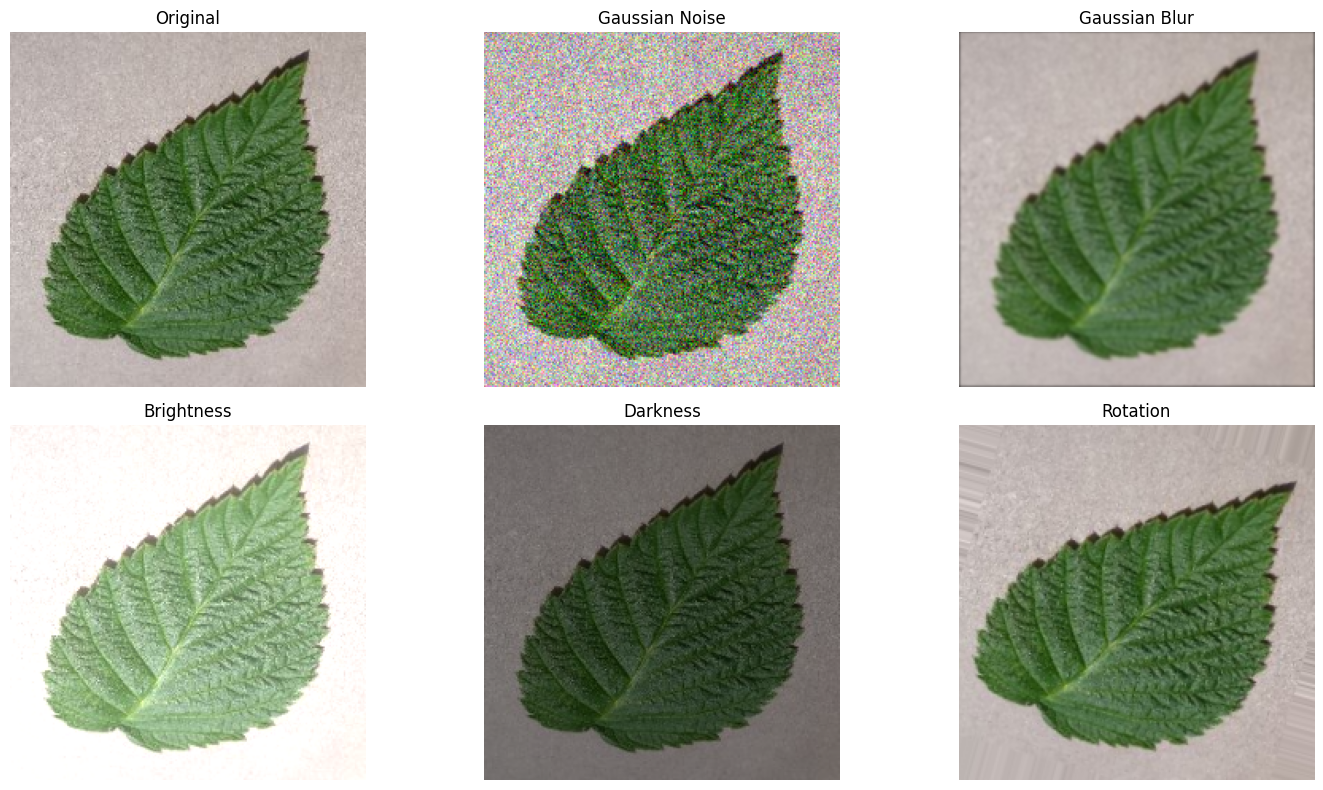

✅ Robustness examples saved!
True class: Raspberry___healthy


In [ ]:

import matplotlib.pyplot as plt
import tensorflow as tf
import os

# Get one image from test dataset
for images, labels in test_ds.take(1):
    original_image = images[0]
    original_label = labels[0]

# Apply distortions
distorted_images = [
    original_image,
    add_gaussian_noise(original_image, severity=0.15),
    add_gaussian_blur(original_image, severity=1.0),
    increase_brightness(original_image, severity=0.3),
    decrease_brightness(original_image, severity=0.4),
    rotate_image(original_image, severity=0.1)
]

titles = [
    "Original",
    "Gaussian Noise",
    "Gaussian Blur",
    "Brightness",
    "Darkness",
    "Rotation"
]

# Display images
plt.figure(figsize=(15, 8))

for i, (img, title) in enumerate(zip(distorted_images, titles)):
    plt.subplot(2, 3, i + 1)

    plt.imshow(
        tf.clip_by_value(img, 0, 255).numpy().astype("uint8")
    )

    plt.title(title)
    plt.axis("off")

plt.tight_layout()

# Save figure
plot_dir = os.path.join(PROJECT_DIR, "plots")
os.makedirs(plot_dir, exist_ok=True)

plt.savefig(
    os.path.join(plot_dir, "robustness_examples.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Robustness examples saved!")
print("True class:", class_names[int(original_label.numpy())])


In [ ]:

import tensorflow as tf
import numpy as np

SEED = 42

# Deterministic Gaussian noise
def fixed_gaussian_noise(image, index, severity=0.1):
    seed = tf.stack([
        tf.constant(SEED, dtype=tf.int32),
        tf.cast(index, tf.int32)
    ])

    noise = tf.random.stateless_normal(
        tf.shape(image),
        seed=seed,
        stddev=severity * 255.0
    )

    return tf.clip_by_value(
        image + noise, 0.0, 255.0
    )


# Fixed rotation (90 degrees)
def fixed_rotation(image, severity=1):
    return tf.image.rot90(image, k=severity)


# Apply distortions consistently
def apply_distortion(image, index, distortion):
    if distortion == "noise":
        return fixed_gaussian_noise(image, index, 0.1)

    elif distortion == "blur":
        return add_gaussian_blur(image, 1.0)

    elif distortion == "brightness":
        return increase_brightness(image, 0.2)

    elif distortion == "darkness":
        return decrease_brightness(image, 0.3)

    elif distortion == "rotation":
        return fixed_rotation(image, 1)

    return image


print("✅ Deterministic robustness functions ready!")


✅ Deterministic robustness functions ready!


In [ ]:

import tensorflow as tf

AUTOTUNE = tf.data.AUTOTUNE

# Use the saved test paths in their original order
test_full_paths, test_labels = prepare_paths_and_labels(
    test_paths
)

def create_robustness_dataset(distortion):
    # Assign a fixed index to every test image
    ds = tf.data.Dataset.from_tensor_slices(
        (test_full_paths, test_labels)
    )

    ds = ds.enumerate()

    def process_image(index, data):
        path, label = data

        image, label = load_image(path, label)

        image = apply_distortion(
            image,
            index,
            distortion
        )

        return image, label

    ds = ds.map(
        process_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds


# Create five distorted test datasets
robustness_datasets = {
    "noise": create_robustness_dataset("noise"),
    "blur": create_robustness_dataset("blur"),
    "brightness": create_robustness_dataset("brightness"),
    "darkness": create_robustness_dataset("darkness"),
    "rotation": create_robustness_dataset("rotation")
}

print("✅ Robustness datasets created successfully!")

for name, dataset in robustness_datasets.items():
    print(name, "batches:", len(dataset))


✅ Robustness datasets created successfully!
noise batches: 335
blur batches: 335
brightness batches: 335
darkness batches: 335
rotation batches: 335


In [ ]:

import os
import json
import pandas as pd

PROJECT_DIR = "/content/drive/MyDrive/Plant_Disease_Project"

results_dir = os.path.join(PROJECT_DIR, "results")
os.makedirs(results_dir, exist_ok=True)

# Clean test accuracies from our previous evaluation
clean_baseline = float(baseline_acc)
clean_augmented = float(augmented_acc)

robustness_results = []

for distortion_name, dataset in robustness_datasets.items():

    print(f"\n===== Testing {distortion_name.upper()} =====")

    # Evaluate baseline
    baseline_loss_dist, baseline_acc_dist = (
        baseline_best_model.evaluate(
            dataset,
            verbose=0
        )
    )

    # Evaluate augmented model
    augmented_loss_dist, augmented_acc_dist = (
        augmented_best_model.evaluate(
            dataset,
            verbose=0
        )
    )

    # Accuracy drops in percentage points
    baseline_drop = (
        clean_baseline - baseline_acc_dist
    ) * 100

    augmented_drop = (
        clean_augmented - augmented_acc_dist
    ) * 100

    robustness_results.append({
        "Distortion": distortion_name,
        "Baseline Accuracy (%)": round(
            baseline_acc_dist * 100, 2
        ),
        "Augmented Accuracy (%)": round(
            augmented_acc_dist * 100, 2
        ),
        "Baseline Drop (pp)": round(
            baseline_drop, 2
        ),
        "Augmented Drop (pp)": round(
            augmented_drop, 2
        )
    })

    print(
        "Baseline Accuracy:",
        round(baseline_acc_dist * 100, 2), "%"
    )

    print(
        "Augmented Accuracy:",
        round(augmented_acc_dist * 100, 2), "%"
    )

# Create results table
robustness_df = pd.DataFrame(robustness_results)

print("\n===== ROBUSTNESS COMPARISON =====")
print(robustness_df.to_string(index=False))

# Save results in Google Drive
csv_path = os.path.join(
    results_dir,
    "robustness_results.csv"
)

robustness_df.to_csv(csv_path, index=False)

print("\n✅ Robustness results saved!")
print("Saved at:", csv_path)



===== Testing NOISE =====
Baseline Accuracy: 79.93 %
Augmented Accuracy: 79.2 %

===== Testing BLUR =====
Baseline Accuracy: 89.25 %
Augmented Accuracy: 90.86 %

===== Testing BRIGHTNESS =====
Baseline Accuracy: 97.15 %
Augmented Accuracy: 95.65 %

===== Testing DARKNESS =====
Baseline Accuracy: 97.13 %
Augmented Accuracy: 95.34 %

===== Testing ROTATION =====
Baseline Accuracy: 91.19 %
Augmented Accuracy: 94.05 %

===== ROBUSTNESS COMPARISON =====
Distortion  Baseline Accuracy (%)  Augmented Accuracy (%)  Baseline Drop (pp)  Augmented Drop (pp)
     noise                  79.93                   79.20               17.63                16.99
      blur                  89.25                   90.86                8.31                 5.32
brightness                  97.15                   95.65                0.41                 0.53
  darkness                  97.13                   95.34                0.43                 0.84
  rotation                  91.19                  

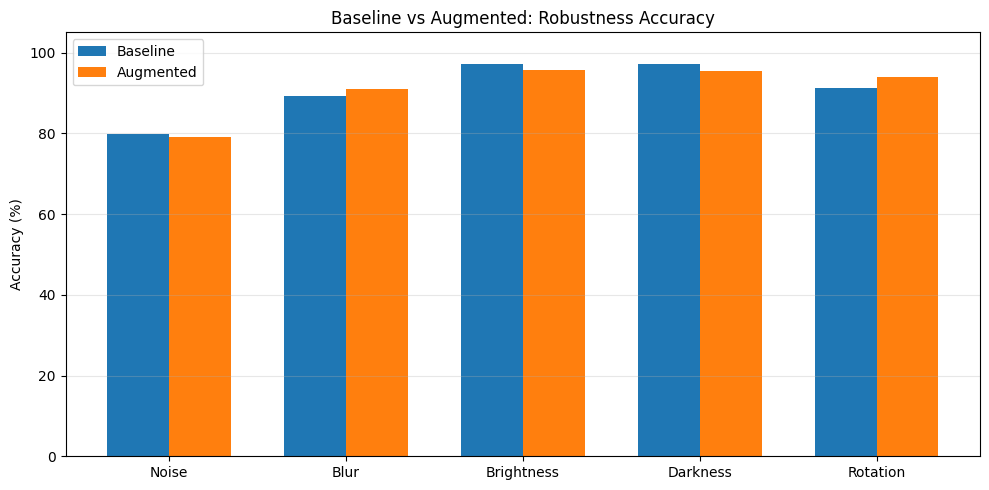

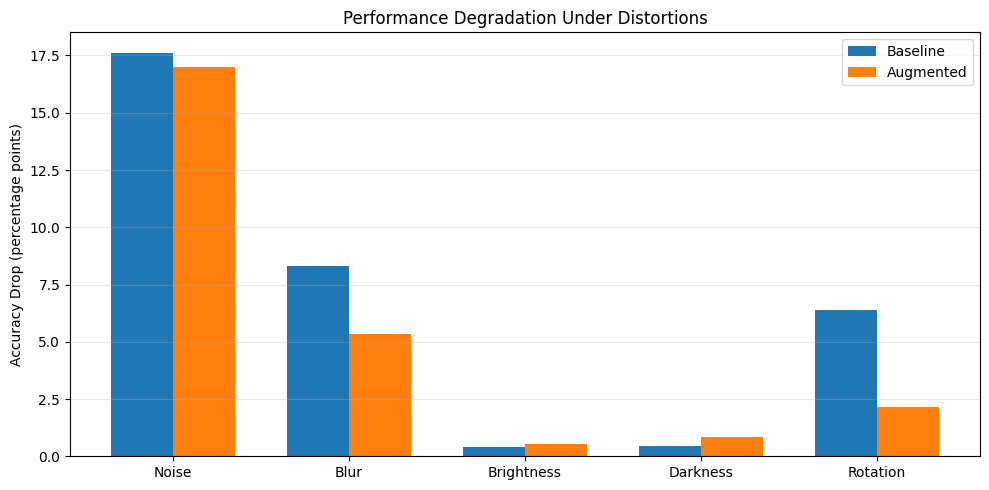

✅ Robustness plots saved successfully!


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

PROJECT_DIR = "/content/drive/MyDrive/Plant_Disease_Project"

results_path = os.path.join(
    PROJECT_DIR, "results", "robustness_results.csv"
)

plots_dir = os.path.join(PROJECT_DIR, "plots")
os.makedirs(plots_dir, exist_ok=True)

df = pd.read_csv(results_path)

names = df["Distortion"].str.capitalize()
x = np.arange(len(names))
width = 0.35

# Figure 1: Robustness Accuracy
plt.figure(figsize=(10, 5))

plt.bar(
    x - width/2,
    df["Baseline Accuracy (%)"],
    width,
    label="Baseline"
)

plt.bar(
    x + width/2,
    df["Augmented Accuracy (%)"],
    width,
    label="Augmented"
)

plt.xticks(x, names)
plt.ylabel("Accuracy (%)")
plt.title("Baseline vs Augmented: Robustness Accuracy")
plt.ylim(0, 105)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(plots_dir, "robustness_accuracy.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Figure 2: Accuracy Drop
plt.figure(figsize=(10, 5))

plt.bar(
    x - width/2,
    df["Baseline Drop (pp)"],
    width,
    label="Baseline"
)

plt.bar(
    x + width/2,
    df["Augmented Drop (pp)"],
    width,
    label="Augmented"
)

plt.xticks(x, names)
plt.ylabel("Accuracy Drop (percentage points)")
plt.title("Performance Degradation Under Distortions")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(plots_dir, "robustness_accuracy_drop.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Robustness plots saved successfully!")


In [ ]:

import numpy as np
import pandas as pd
import os

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_recall_fscore_support
)

# True labels in the same order as test_ds
y_true = np.array([
    class_to_index[p.split("/")[2]]
    for p in test_paths
])

results_dir = os.path.join(PROJECT_DIR, "results")
os.makedirs(results_dir, exist_ok=True)

evaluation_summary = []

models = {
    "Baseline": baseline_best_model,
    "Augmented": augmented_best_model
}

for model_name, model in models.items():

    print(f"\n===== {model_name} Evaluation =====")

    predictions = model.predict(test_ds, verbose=1)
    y_pred = np.argmax(predictions, axis=1)

    accuracy = accuracy_score(y_true, y_pred)

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    evaluation_summary.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1-score": f1
    })

    report = classification_report(
        y_true,
        y_pred,
        labels=np.arange(num_classes),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    pd.DataFrame(report).transpose().to_csv(
        os.path.join(
            results_dir,
            f"{model_name.lower()}_classification_report.csv"
        )
    )

# Compare both models
evaluation_df = pd.DataFrame(evaluation_summary)

print("\n===== FINAL CLASSIFICATION METRICS =====")
print(evaluation_df.to_string(index=False))

evaluation_df.to_csv(
    os.path.join(results_dir, "classification_metrics.csv"),
    index=False
)

print("\n✅ Classification metrics saved successfully!")



===== Baseline Evaluation =====
335/335 ━━━━━━━━━━━━━━━━━━━━ 26s 54ms/step

===== Augmented Evaluation =====
335/335 ━━━━━━━━━━━━━━━━━━━━ 30s 82ms/step

===== FINAL CLASSIFICATION METRICS =====
    Model  Accuracy  Macro Precision  Macro Recall  Macro F1-score
 Baseline  0.975628         0.970888      0.968113        0.969309
Augmented  0.961808         0.956891      0.952604        0.953213

✅ Classification metrics saved successfully!


In [ ]:

import os

PROJECT_DIR = "/content/drive/MyDrive/Plant_Disease_Project"

files_to_check = [
    "data.zip",
    "data_splits.json",
    "checkpoints/baseline_best.keras",
    "checkpoints/augmented_best.keras",
    "results/clean_test_results.json",
    "results/robustness_results.csv",
    "plots/robustness_accuracy.png",
    "plots/robustness_accuracy_drop.png"
]

print("===== PROJECT BACKUP CHECK =====")

for file in files_to_check:
    path = os.path.join(PROJECT_DIR, file)

    if os.path.isfile(path):
        print(" Saved:", file)
    else:
        print(" Missing:", file)


===== PROJECT BACKUP CHECK =====
 Saved: data.zip
 Saved: data_splits.json
 Saved: checkpoints/baseline_best.keras
 Saved: checkpoints/augmented_best.keras
 Saved: results/clean_test_results.json
 Saved: results/robustness_results.csv
 Saved: plots/robustness_accuracy.png
 Saved: plots/robustness_accuracy_drop.png


In [ ]:

import os

results_dir = "/content/drive/MyDrive/Plant_Disease_Project/results"

for filename in [
    "classification_metrics.csv",
    "baseline_classification_report.csv",
    "augmented_classification_report.csv"
]:
    print(
        filename,
        "✅ Saved" if os.path.isfile(
            os.path.join(results_dir, filename)
        ) else "❌ Missing"
    )


classification_metrics.csv ✅ Saved
baseline_classification_report.csv ✅ Saved
augmented_classification_report.csv ✅ Saved


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Plant_Disease_Project/checkpoints"

print(os.listdir(PROJECT_DIR))

[]


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Plant_Disease_Project"

for root, dirs, files in os.walk(PROJECT_DIR):
    for file in files:
        if file.endswith(".keras"):
            print(os.path.join(root, file))

335/335 ━━━━━━━━━━━━━━━━━━━━ 17s 50ms/step


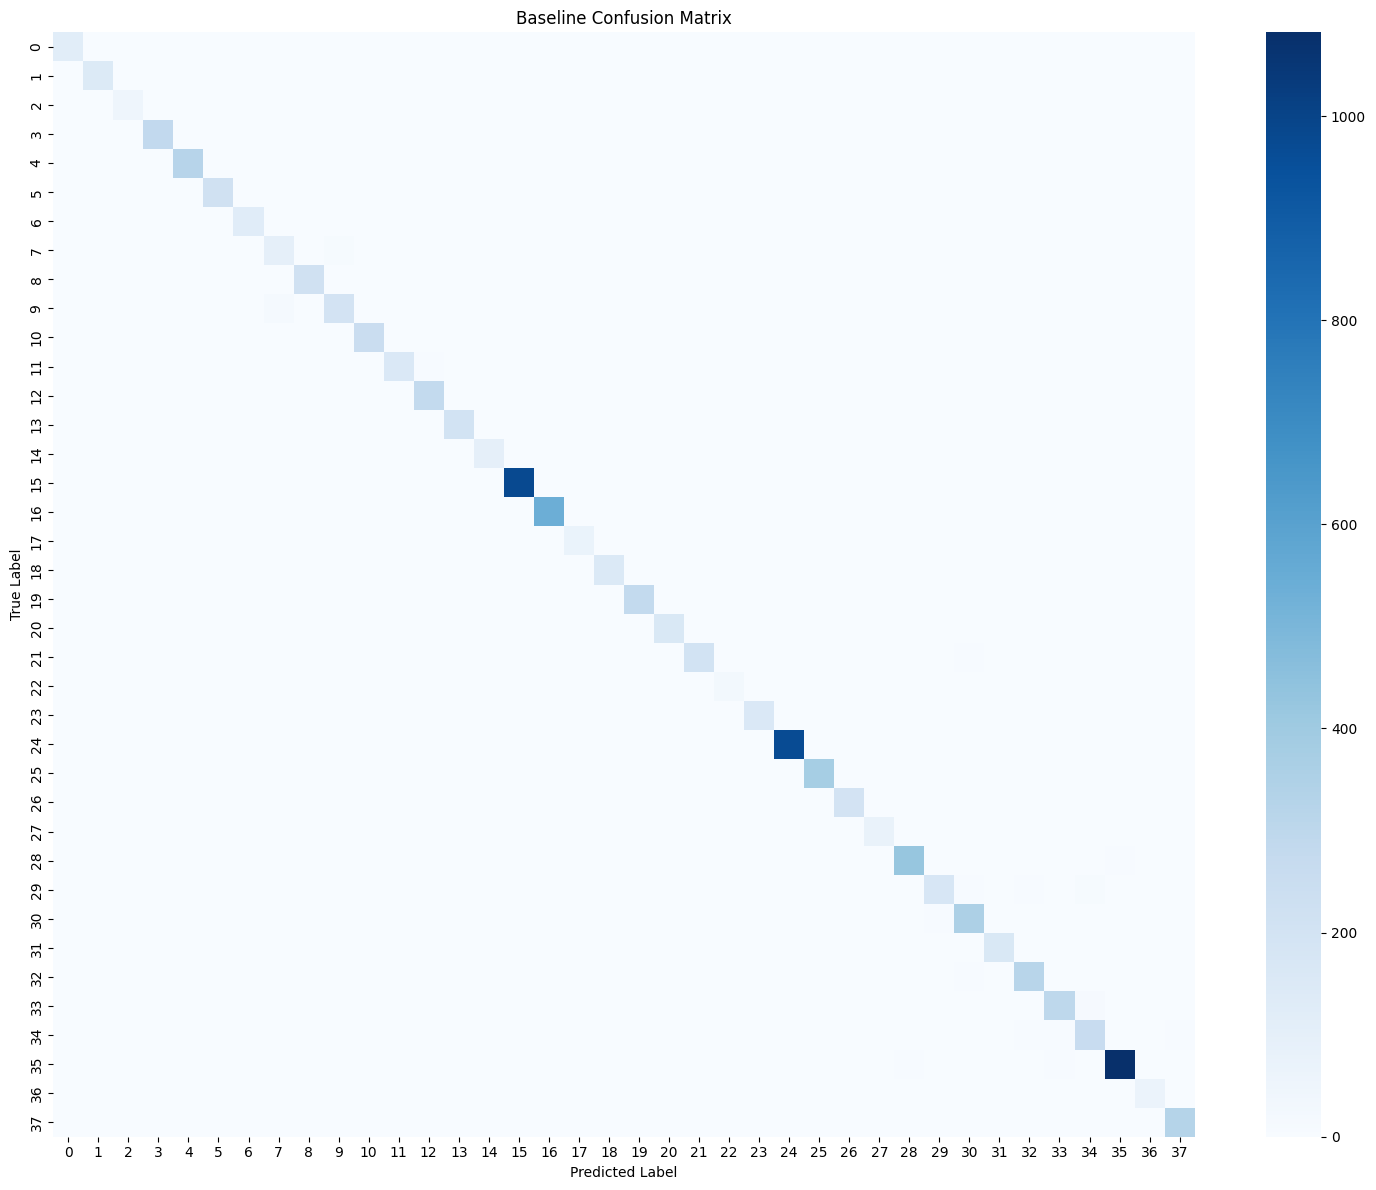

✅ Baseline Confusion Matrix Created


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import os

baseline_predictions = baseline_best_model.predict(
    test_ds,
    verbose=1
)

y_pred_baseline = np.argmax(
    baseline_predictions,
    axis=1
)

cm_baseline = confusion_matrix(
    y_true,
    y_pred_baseline
)

plt.figure(figsize=(15,12))

sns.heatmap(
    cm_baseline,
    cmap="Blues"
)

plt.title("Baseline Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()

print("✅ Baseline Confusion Matrix Created")

335/335 ━━━━━━━━━━━━━━━━━━━━ 27s 79ms/step


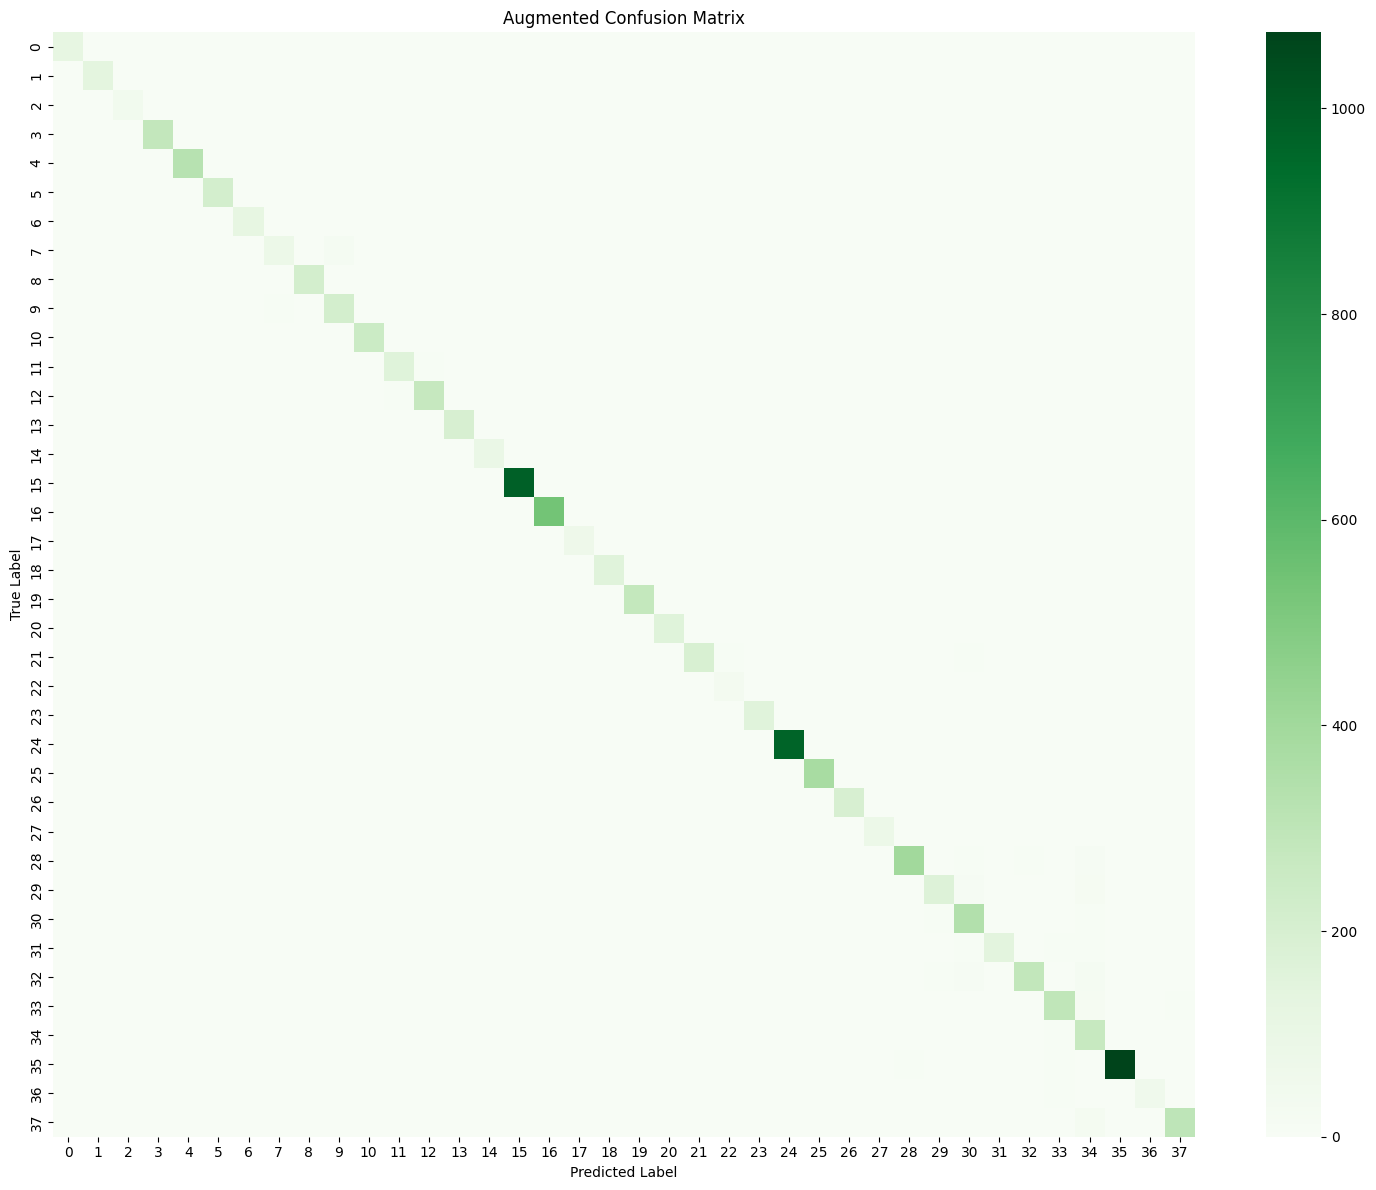

✅ Augmented Confusion Matrix Created


In [ ]:
aug_predictions = augmented_best_model.predict(
    test_ds,
    verbose=1
)

y_pred_aug = np.argmax(
    aug_predictions,
    axis=1
)

cm_aug = confusion_matrix(
    y_true,
    y_pred_aug
)

plt.figure(figsize=(15,12))

sns.heatmap(
    cm_aug,
    cmap="Greens"
)

plt.title("Augmented Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()

print("✅ Augmented Confusion Matrix Created")

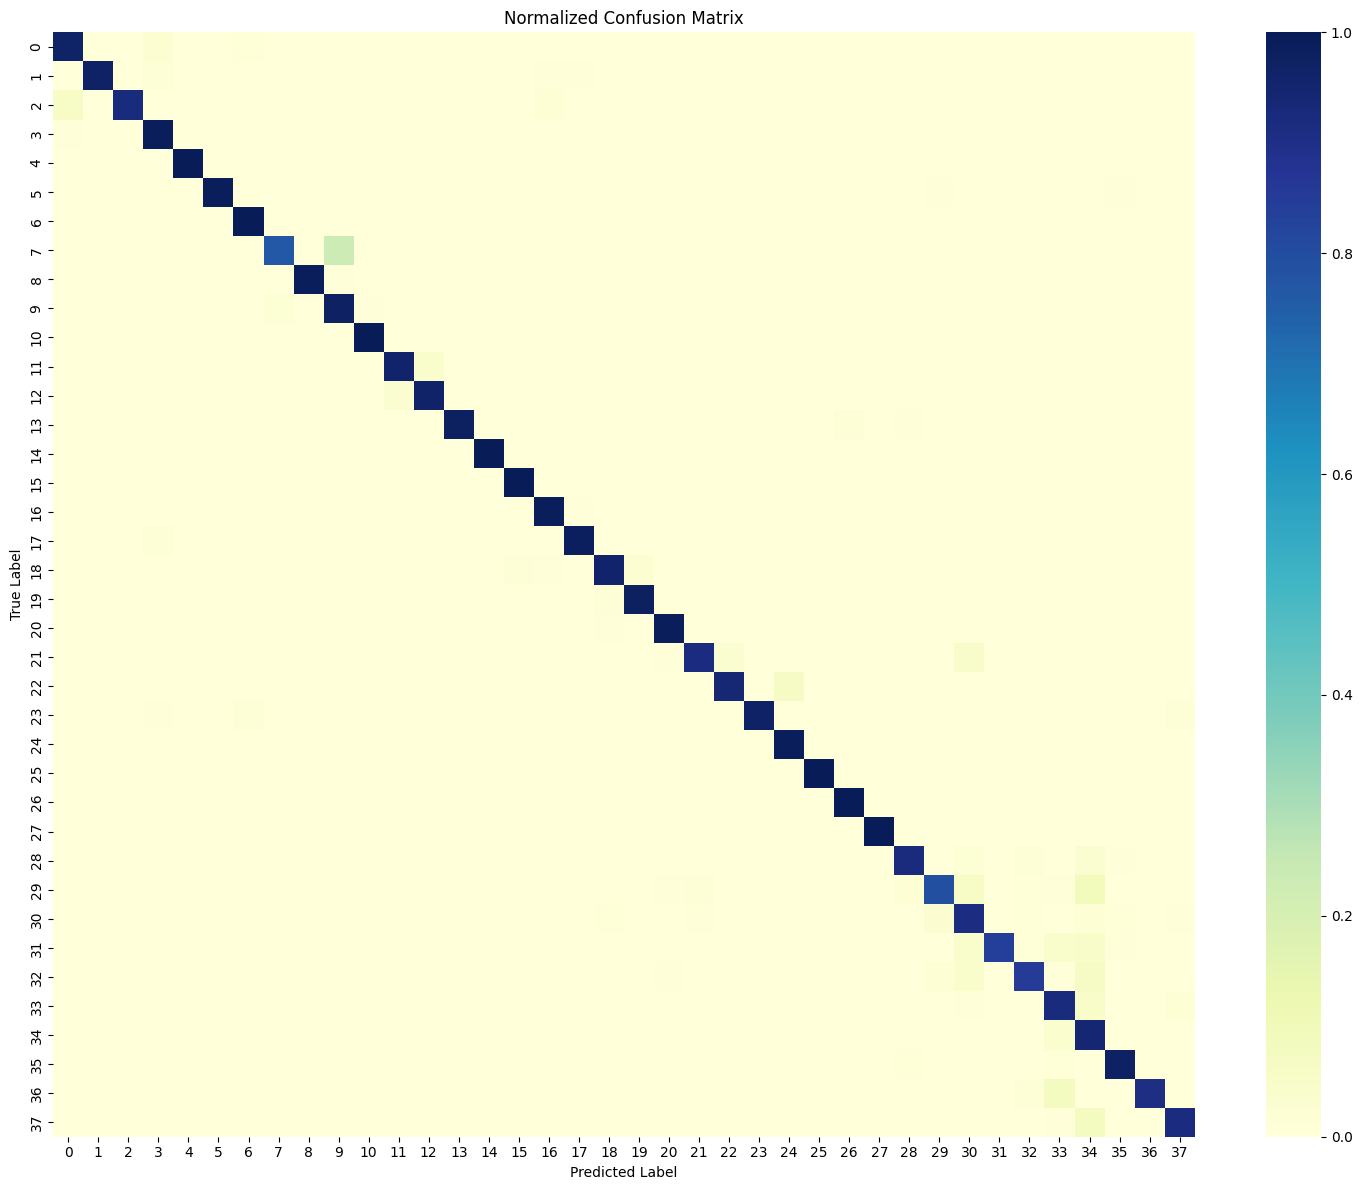

✅ Normalized Confusion Matrix Created


In [ ]:
cm_norm = confusion_matrix(
    y_true,
    y_pred_aug,
    normalize="true"
)

plt.figure(figsize=(15,12))

sns.heatmap(
    cm_norm,
    cmap="YlGnBu"
)

plt.title("Normalized Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()

print("✅ Normalized Confusion Matrix Created")